In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt

r = pd.read_csv("../challenge_data/vm_cpu_readings.csv.gz")
meta = pd.read_csv("../challenge_data/vm_metadata.csv.gz")
print(r.shape, meta.shape)
r.head()

(1340000, 5) (10000, 11)


,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [2]:
y = (r.groupby("timestamp")
       .agg(active_vm_count=("vm_id", "nunique"),
            aggregate_cpu_utilization=("avg_cpu", "mean"))
       .sort_index())

y_train = y.iloc[:110]   # first 110 timestamps
y_hold  = y.iloc[110:]   # last 24: do NOT use for fitting, tuning or choosing models
print(len(y_train), len(y_hold))
y_train.describe()

110 24


,active_vm_count,aggregate_cpu_utilization
count,110.0,110.000000
mean,10000.0,9.414089
std,0.0,0.193568
min,10000.0,9.111634
25%,10000.0,9.288952
50%,10000.0,9.378121
75%,10000.0,9.507673
max,10000.0,9.912175


In [3]:
print("duplicates (vm, time):", r.duplicated(["vm_id", "timestamp"]).sum())
print("missing values:\n", r.isna().sum())
print("time steps:", pd.Series(np.diff(sorted(r.timestamp.unique()))).value_counts().to_dict())
print("readings per VM:", r.groupby("vm_id").size().value_counts().to_dict())
print("avg_cpu range:", r.avg_cpu.min(), r.avg_cpu.max())

duplicates (vm, time): 0
missing values:
 timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64
time steps: {300: 133}
readings per VM: {134: 10000}
avg_cpu range: 0.0071589216268651 99.48802665399457


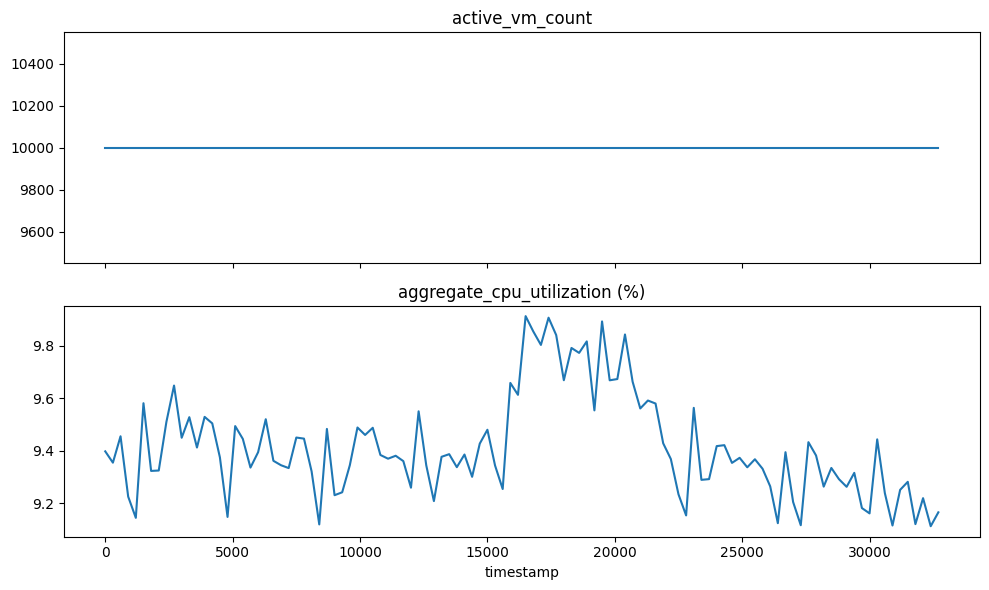

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
y_train.active_vm_count.plot(ax=ax[0], title="active_vm_count")
y_train.aggregate_cpu_utilization.plot(ax=ax[1], title="aggregate_cpu_utilization (%)")
plt.tight_layout()

count    10000.000000
mean         9.414089
std         13.051504
min          0.007345
25%          2.869327
50%          5.501660
75%          9.972827
max         99.272951
Name: avg_cpu, dtype: float64
0.50     5.501660
0.90    19.739861
0.99    79.623001
Name: avg_cpu, dtype: float64
share of total CPU from the top 10% of VMs: 0.435


<Axes: title={'center': 'Mean avg_cpu per VM (log count)'}, ylabel='Frequency'>

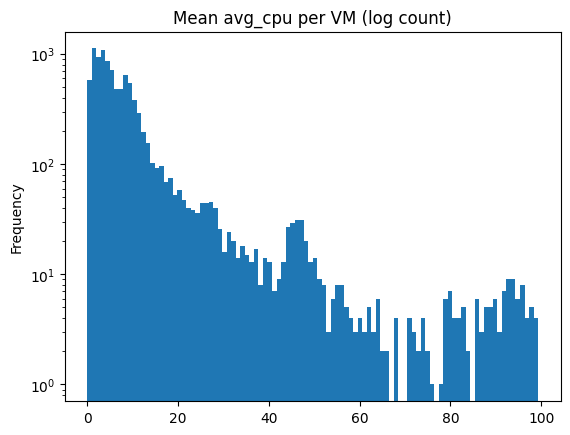

In [5]:
train_ts = y_train.index
rt = r[r.timestamp.isin(train_ts)]

vm_mean = rt.groupby("vm_id").avg_cpu.mean()
print(vm_mean.describe())
print(vm_mean.quantile([.5, .9, .99]))
top10 = vm_mean.sort_values(ascending=False).head(1000).sum() / vm_mean.sum()
print("share of total CPU from the top 10% of VMs:", round(top10, 3))
vm_mean.plot.hist(bins=100, log=True, title="Mean avg_cpu per VM (log count)")

                    count       mean    median        std
vm_category                                              
Delay-insensitive  679800   8.257266  5.160160  12.036259
Interactive        340010  11.505150  5.295715  16.950810
Unknown             80190  10.354689  3.415575  17.837379


<Axes: title={'center': 'Mean CPU by VM category'}, xlabel='timestamp'>

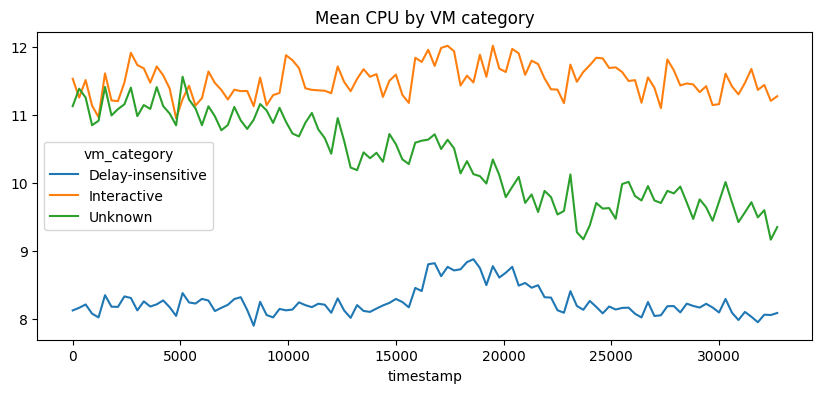

In [6]:
m = meta[["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]]
rt = rt.merge(m, on="vm_id")

print(rt.groupby("vm_category").avg_cpu.agg(["count", "mean", "median", "std"]))
seg = rt.groupby(["timestamp", "vm_category"]).avg_cpu.mean().unstack()
seg.plot(figsize=(10, 4), title="Mean CPU by VM category")

In [7]:
s = y_train.aggregate_cpu_utilization
for lag in [1, 2, 3, 6, 12, 24]:
    print(lag, round(s.autocorr(lag), 3))

1 0.667
2 0.606
3 0.681
6 0.477
12 0.367
24 -0.026


In [8]:
bump = rt[(rt.timestamp >= 15000) & (rt.timestamp <= 21000)].groupby("vm_id").avg_cpu.mean()
rest = rt[(rt.timestamp < 15000) | (rt.timestamp > 21000)].groupby("vm_id").avg_cpu.mean()

delta = (bump - rest).sort_values(ascending=False)   # change per VM
print(delta.describe())
print("share of the total increase from the top 100 VMs:",
      round(delta.head(100).sum() / delta.sum(), 3))
print("VMs that went up:", (delta > 0).sum(), " went down:", (delta < 0).sum())

count    10000.000000
mean         0.344952
std          3.669130
min        -45.927435
25%         -0.211500
50%         -0.013661
75%          0.289742
max         57.509369
Name: avg_cpu, dtype: float64
share of the total increase from the top 100 VMs: 0.742
VMs that went up: 4707  went down: 5293


In [9]:
s = y_train.aggregate_cpu_utilization.values   # 110 training points
H = 24                                         # forecast 24 steps ahead

def last_value(history, h=H):
    return np.repeat(history[-1], h)

def rolling_origin(forecast_fn, series, first_origin=60, h=H):
    errs = []
    for t in range(first_origin, len(series) - h + 1):
        pred = forecast_fn(series[:t], h)      # sees only data before time t
        actual = series[t:t + h]
        errs.append(actual - pred)
    return np.array(errs)                      # rows = origins, columns = forecast steps

e = rolling_origin(last_value, s)
print("origins tested:", e.shape[0])
print("last_value  MAE:", round(np.abs(e).mean(), 4),
      " RMSE:", round(np.sqrt((e ** 2).mean()), 4))
print("MAE by forecast step:", np.round(np.abs(e).mean(axis=0), 3))

origins tested: 27
last_value  MAE: 0.2168  RMSE: 0.2709
MAE by forecast step: [0.115 0.125 0.131 0.148 0.169 0.164 0.181 0.189 0.186 0.21  0.213 0.201
 0.237 0.256 0.242 0.259 0.273 0.26  0.268 0.264 0.264 0.282 0.288 0.276]


In [10]:
def moving_average(k):
    def f(history, h=H):
        return np.repeat(history[-k:].mean(), h)
    return f

for k in [3, 6, 12, 24]:
    e_k = rolling_origin(moving_average(k), s)
    print(k, round(np.abs(e_k).mean(), 4), round(np.sqrt((e_k ** 2).mean()), 4))

3 0.2184 0.272
6 0.2367 0.2901
12 0.2619 0.306
24 0.2739 0.3022


In [11]:
def hist_mean(history, h=H):
    return np.repeat(history.mean(), h)

def ar1_to_mean(history, h=H):
    m = history.mean()
    x = history - m
    phi = np.clip((x[1:] * x[:-1]).sum() / (x[:-1] ** 2).sum(), 0, 0.99)
    return m + x[-1] * phi ** np.arange(1, h + 1)

base = np.abs(rolling_origin(last_value, s)).mean()
for name, fn in [("hist_mean", hist_mean), ("ar1_to_mean", ar1_to_mean)]:
    e_ = rolling_origin(fn, s)
    mae_ = np.abs(e_).mean()
    print(name, "MAE:", round(mae_, 4),
          "RMSE:", round(np.sqrt((e_ ** 2).mean()), 4),
          "vs last_value:", f"{(1 - mae_ / base) * 100:.1f}%")
    print("  MAE by step:", np.round(np.abs(e_).mean(axis=0), 3))

hist_mean MAE: 0.1716 RMSE: 0.1991 vs last_value: 20.9%
  MAE by step: [0.183 0.184 0.185 0.177 0.174 0.184 0.169 0.164 0.164 0.154 0.152 0.155
 0.154 0.158 0.168 0.166 0.166 0.168 0.169 0.17  0.176 0.183 0.195 0.202]
ar1_to_mean MAE: 0.163 RMSE: 0.191 vs last_value: 24.8%
  MAE by step: [0.114 0.134 0.146 0.154 0.161 0.177 0.165 0.163 0.162 0.154 0.152 0.155
 0.154 0.158 0.168 0.166 0.166 0.168 0.169 0.17  0.176 0.183 0.195 0.202]


In [12]:
from sklearn.linear_model import Ridge

def ridge_ar(p=3, alpha=1.0):
    def f(history, h=H):
        x = np.asarray(history)
        m = x.mean()
        z = x - m
        X = np.column_stack([z[i:len(z) - p + i] for i in range(p)])  # oldest ... newest
        yv = z[p:]
        model = Ridge(alpha=alpha).fit(X, yv)
        buf = list(z[-p:])
        out = []
        for _ in range(h):
            nxt = model.predict(np.array(buf[-p:]).reshape(1, -1))[0]
            out.append(nxt)
            buf.append(nxt)
        return m + np.array(out)
    return f

base_lv = np.abs(rolling_origin(last_value, s)).mean()
base_ar = np.abs(rolling_origin(ar1_to_mean, s)).mean()
for p in [2, 3, 6]:
    e_ = rolling_origin(ridge_ar(p=p, alpha=1.0), s)
    mae_ = np.abs(e_).mean()
    print(f"ridge p={p}: MAE {mae_:.4f}  RMSE {np.sqrt((e_**2).mean()):.4f}  "
          f"vs last_value {(1 - mae_/base_lv)*100:.1f}%  vs ar1 {(1 - mae_/base_ar)*100:.1f}%")

ridge p=2: MAE 0.1658  RMSE 0.1934  vs last_value 23.5%  vs ar1 -1.7%
ridge p=3: MAE 0.1625  RMSE 0.1921  vs last_value 25.1%  vs ar1 0.3%
ridge p=6: MAE 0.1761  RMSE 0.2074  vs last_value 18.8%  vs ar1 -8.1%


In [13]:
fn = ar1_to_mean
rows = []
for t in range(60, len(s) - H + 1):
    pred = fn(s[:t], H)
    for k in range(H):
        rows.append((t, k + 1, t + k, s[t + k], pred[k]))
d = pd.DataFrame(rows, columns=["origin", "step", "target_idx", "actual", "pred"])
d["err"] = d.actual - d.pred
d["abs_err"] = d.err.abs()

d["in_bump"] = d.target_idx.between(50, 70)       # 15,000 to 21,000 seconds
thr = np.quantile(s[:60], 0.75)                   # threshold uses only data before the first origin
d["high_load"] = d.actual > thr

print(d.groupby("in_bump").abs_err.agg(["count", "mean"]))
print(d.groupby("high_load").agg(n=("abs_err", "count"), mae=("abs_err", "mean"), bias=("err", "mean")))

         count      mean
in_bump                 
False      582  0.159021
True        66  0.198010
             n       mae      bias
high_load                         
False      539  0.163108 -0.162675
True       109  0.162422  0.155148


In [14]:
E = d.pivot(index="origin", columns="step", values="err").values   # origins x steps
lo = np.quantile(E, 0.05, axis=0)
hi = np.quantile(E, 0.95, axis=0)
print("5% quantile of error by step:", np.round(lo, 2))
print("95% quantile of error by step:", np.round(hi, 2))
print("in-sample coverage:", ((E >= lo) & (E <= hi)).mean().round(3))

5% quantile of error by step: [-0.17 -0.22 -0.3  -0.3  -0.31 -0.33 -0.34 -0.34 -0.33 -0.33 -0.34 -0.33
 -0.33 -0.34 -0.34 -0.34 -0.34 -0.35 -0.35 -0.35 -0.35 -0.35 -0.35 -0.35]
95% quantile of error by step: [ 0.29  0.28  0.31  0.36  0.3   0.33  0.23  0.23  0.2   0.14  0.13  0.13
  0.07 -0.01 -0.04 -0.02 -0.02 -0.02 -0.03 -0.02 -0.02 -0.03 -0.05 -0.05]
in-sample coverage: 0.852


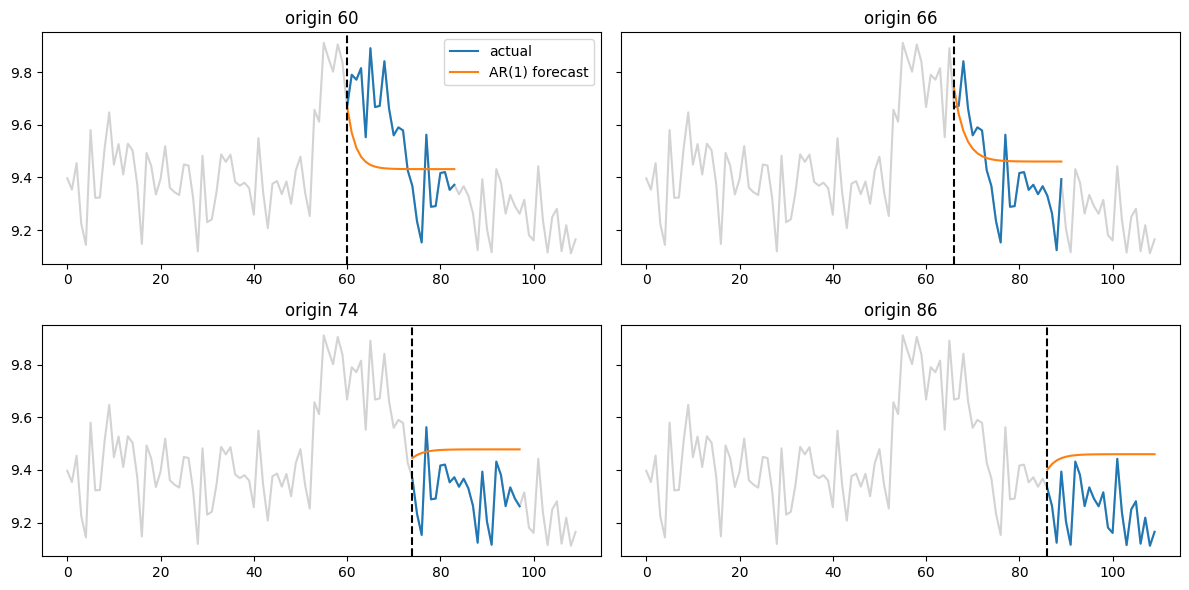

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharey=True)
for ax, t in zip(axes.ravel(), [60, 66, 74, 86]):
    ax.plot(range(len(s)), s, color="lightgray")
    ax.plot(range(t, t + H), s[t:t + H], label="actual")
    ax.plot(range(t, t + H), ar1_to_mean(s[:t], H), label="AR(1) forecast")
    ax.axvline(t, ls="--", color="k")
    ax.set_title(f"origin {t}")
axes[0, 0].legend()
plt.tight_layout()

In [16]:
print("mean error by step:", np.round(E.mean(axis=0), 3))

def ar1_recent_mean(w):
    def f(history, h=H):
        x = np.asarray(history)
        z = x - x.mean()
        phi = np.clip((z[1:] * z[:-1]).sum() / (z[:-1] ** 2).sum(), 0, 0.99)
        m = x[-w:].mean()
        return m + (x[-1] - m) * phi ** np.arange(1, h + 1)
    return f

for w in [24, 36, 48, 60]:
    e_ = rolling_origin(ar1_recent_mean(w), s)
    mae_ = np.abs(e_).mean()
    print(f"w={w}: MAE {mae_:.4f} RMSE {np.sqrt((e_**2).mean()):.4f} "
          f"vs ar1 {(1 - mae_/base_ar)*100:.1f}%  mean err {e_.mean():.3f}")

mean error by step: [ 0.009  0.011 -0.003 -0.01  -0.029 -0.042 -0.058 -0.067 -0.082 -0.1
 -0.114 -0.125 -0.135 -0.15  -0.16  -0.157 -0.157 -0.158 -0.169 -0.17
 -0.176 -0.183 -0.195 -0.202]
w=24: MAE 0.2632 RMSE 0.2934 vs ar1 -61.5%  mean err -0.232
w=36: MAE 0.2218 RMSE 0.2502 vs ar1 -36.1%  mean err -0.179
w=48: MAE 0.1902 RMSE 0.2176 vs ar1 -16.7%  mean err -0.140
w=60: MAE 0.1740 RMSE 0.2016 vs ar1 -6.8%  mean err -0.122
